### Uruchomienie z folderu wizualizacja danych:
- shiny::runApp("life_expectancy/app.R")
- shiny::runApp("digital_distraction/app.R")

In [6]:
install.packages(c(
  "highcharter",
  "sf",
  "rnaturalearth",
  "rnaturalearthdata",
  "janitor",
  "viridis"
), repos = "https://cloud.r-project.org")

Instalowanie pakietów w 'C:/Users/emilk/AppData/Local/R/win-library/4.5'
(ponieważ 'lib' nie jest określony)



instalowanie dodatkowych zależności 'proxy', 'XML', 'TTR', 'timechange', 'e1071', 'wk', 'rlist', 'assertthat', 'zoo', 'broom', 'xts', 'quantmod', 'igraph', 'lubridate', 'rjson', 'classInt', 'DBI', 's2', 'units', 'terra', 'hms', 'snakecase', 'gridExtra'




pakiet 'proxy' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'XML' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'TTR' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'timechange' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'e1071' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'wk' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'rlist' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'assertthat' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'zoo' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'broom' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'xts' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'quantmod' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdzone
pakiet 'igraph' został pomyślnie rozpakowany oraz sumy MD5 zostały sprawdz

In [7]:
library(highcharter)
library(sf)
library(rnaturalearth)
library(rnaturalearthdata)
library(janitor)
library(viridis)

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 

Warning message:
"pakiet 'sf' został zbudowany w wersji R 4.5.3"
Linking to GEOS 3.14.1, GDAL 3.12.1, PROJ 9.7.1; sf_use_s2() is TRUE

Warning message:
"pakiet 'rnaturalearth' został zbudowany w wersji R 4.5.3"
Warning message:
"pakiet 'rnaturalearthdata' został zbudowany w wersji R 4.5.3"

Dołączanie pakietu: 'rnaturalearthdata'


Następujący obiekt został zakryty z 'package:rnaturalearth':

    countries110


Warning message:
"pakiet 'janitor' został zbudowany w wersji R 4.5.3"

Dołączanie pakietu: 'janitor'


Następujące obiekty zostały zakryte z 'package:stats':

    chisq.test, fisher.test


Warning message:
"pakiet 'viridis' został zbudowany w wersji R 4.5.3"
Ładowanie wymaganego pakietu: viridisLite

Warning message:
"pakiet 'viridisLite' został zbudowany w wersji R 4.5.3"


In [2]:
library(ggplot2)

data <- read.csv("digital_distraction_source_dataset.csv",
                 header = TRUE,
                 sep = ",",
                 stringsAsFactors = FALSE)

head(data)

Warning message:
"package 'ggplot2' was built under R version 4.5.3"


,user_id,primary_task,distraction_source,time_of_day,location,distraction_frequency_per_hour,focus_loss_duration_minutes,self_reported_focus_level,uses_focus_tool
,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>
1,1,Online Learning,Messaging Apps,Morning,Office,4,8,3,Yes
2,2,Online Learning,Notifications,Morning,Hostel,7,2,1,Yes
3,3,Working,YouTube,Morning,Hostel,4,23,9,No
4,4,Working,People Around,Evening,Home,13,26,3,No
5,5,Reading,News Websites,Afternoon,Library,13,11,2,Yes
6,6,Coding,Messaging Apps,Evening,Office,10,9,1,No


In [3]:
options(repr.plot.width = 15,
        repr.plot.height = 10)

theme_set(
  theme_minimal(base_size = 14) +
    theme(
      plot.margin = margin(t = 20, r = 40, b = 20, l = 20),
      axis.text.x = element_text(margin = margin(t = 5)),
      axis.text.y = element_text(margin = margin(r = 5)),
      plot.title = element_text(face = "bold", hjust = 0.5)
    )
)

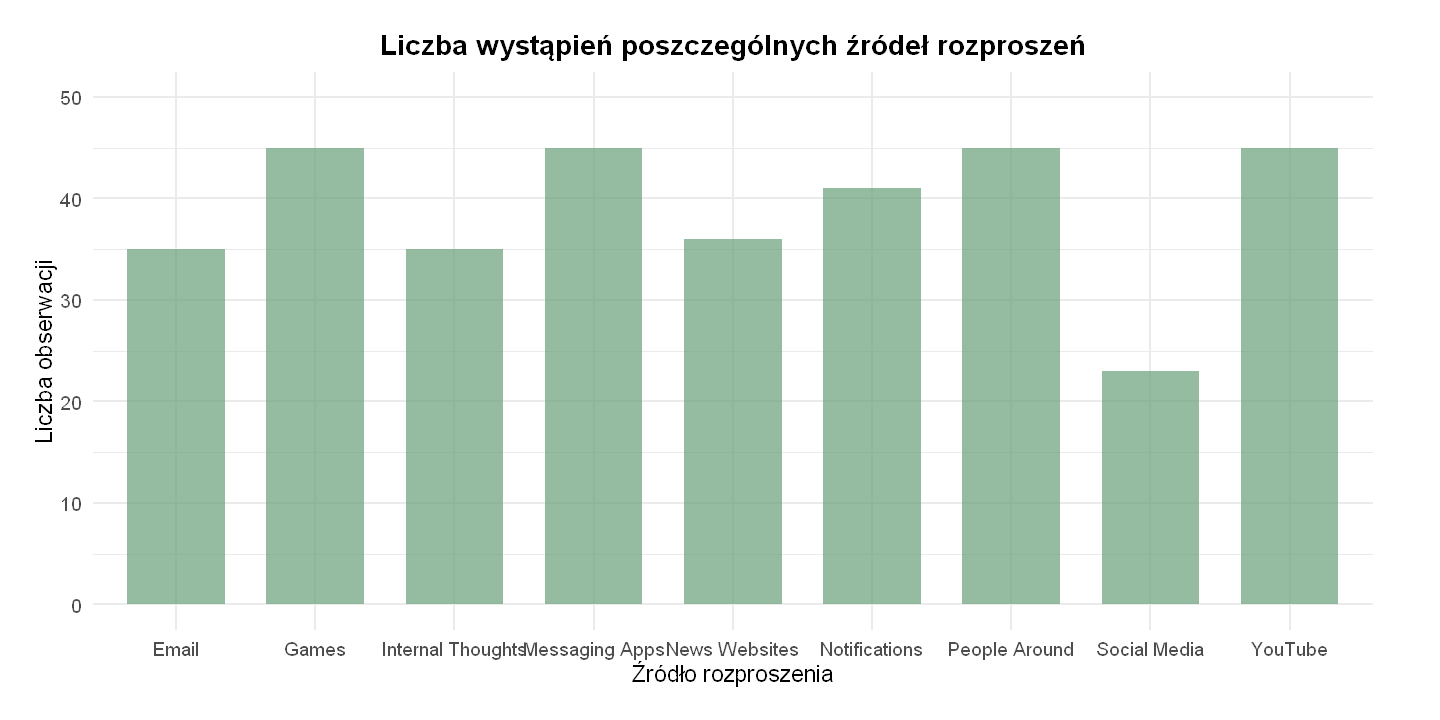

In [ ]:
# Liczba wystąpień poszczególnych źródeł rozproszeń
  ggplot(data, aes(x=distraction_source)) + 
  geom_bar(fill = "#6da37dba", width = 0.7) +
  scale_y_continuous(limits = c(0, 50)) +
  labs(
    title = "Liczba wystąpień poszczególnych źródeł rozproszeń",
    x = "Źródło rozproszenia",
    y = "Liczba obserwacji"
  )


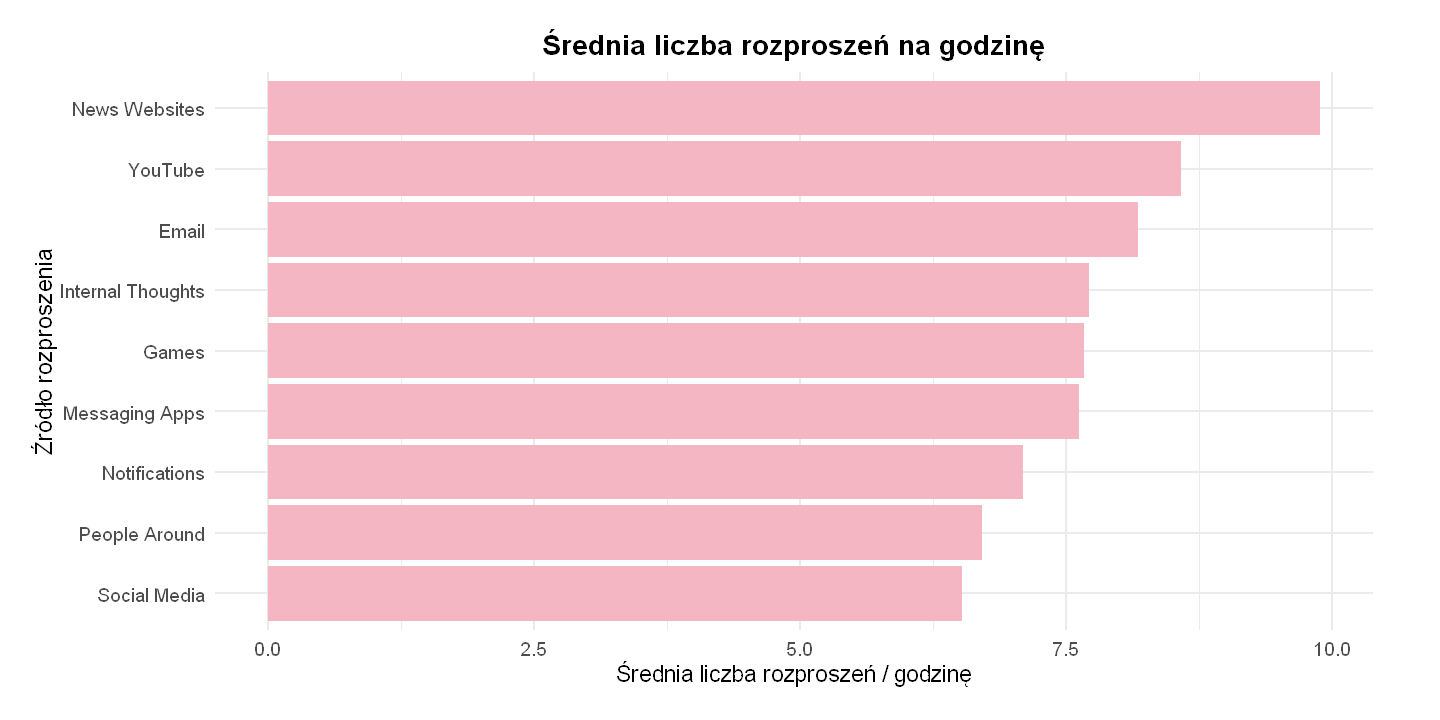

In [38]:
# Średnia liczba rozproszeń na godzinę
ggplot(dane, aes(x = reorder(distraction_source, distraction_frequency_per_hour),
                 y = distraction_frequency_per_hour)) +
  stat_summary(fun = "mean",
               geom = "bar",
               fill = "#F4B6C2") +
  labs(
    title = "Średnia liczba rozproszeń na godzinę",
    x = "Źródło rozproszenia",
    y = "Średnia liczba rozproszeń / godzinę"
  ) +
  coord_flip()


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




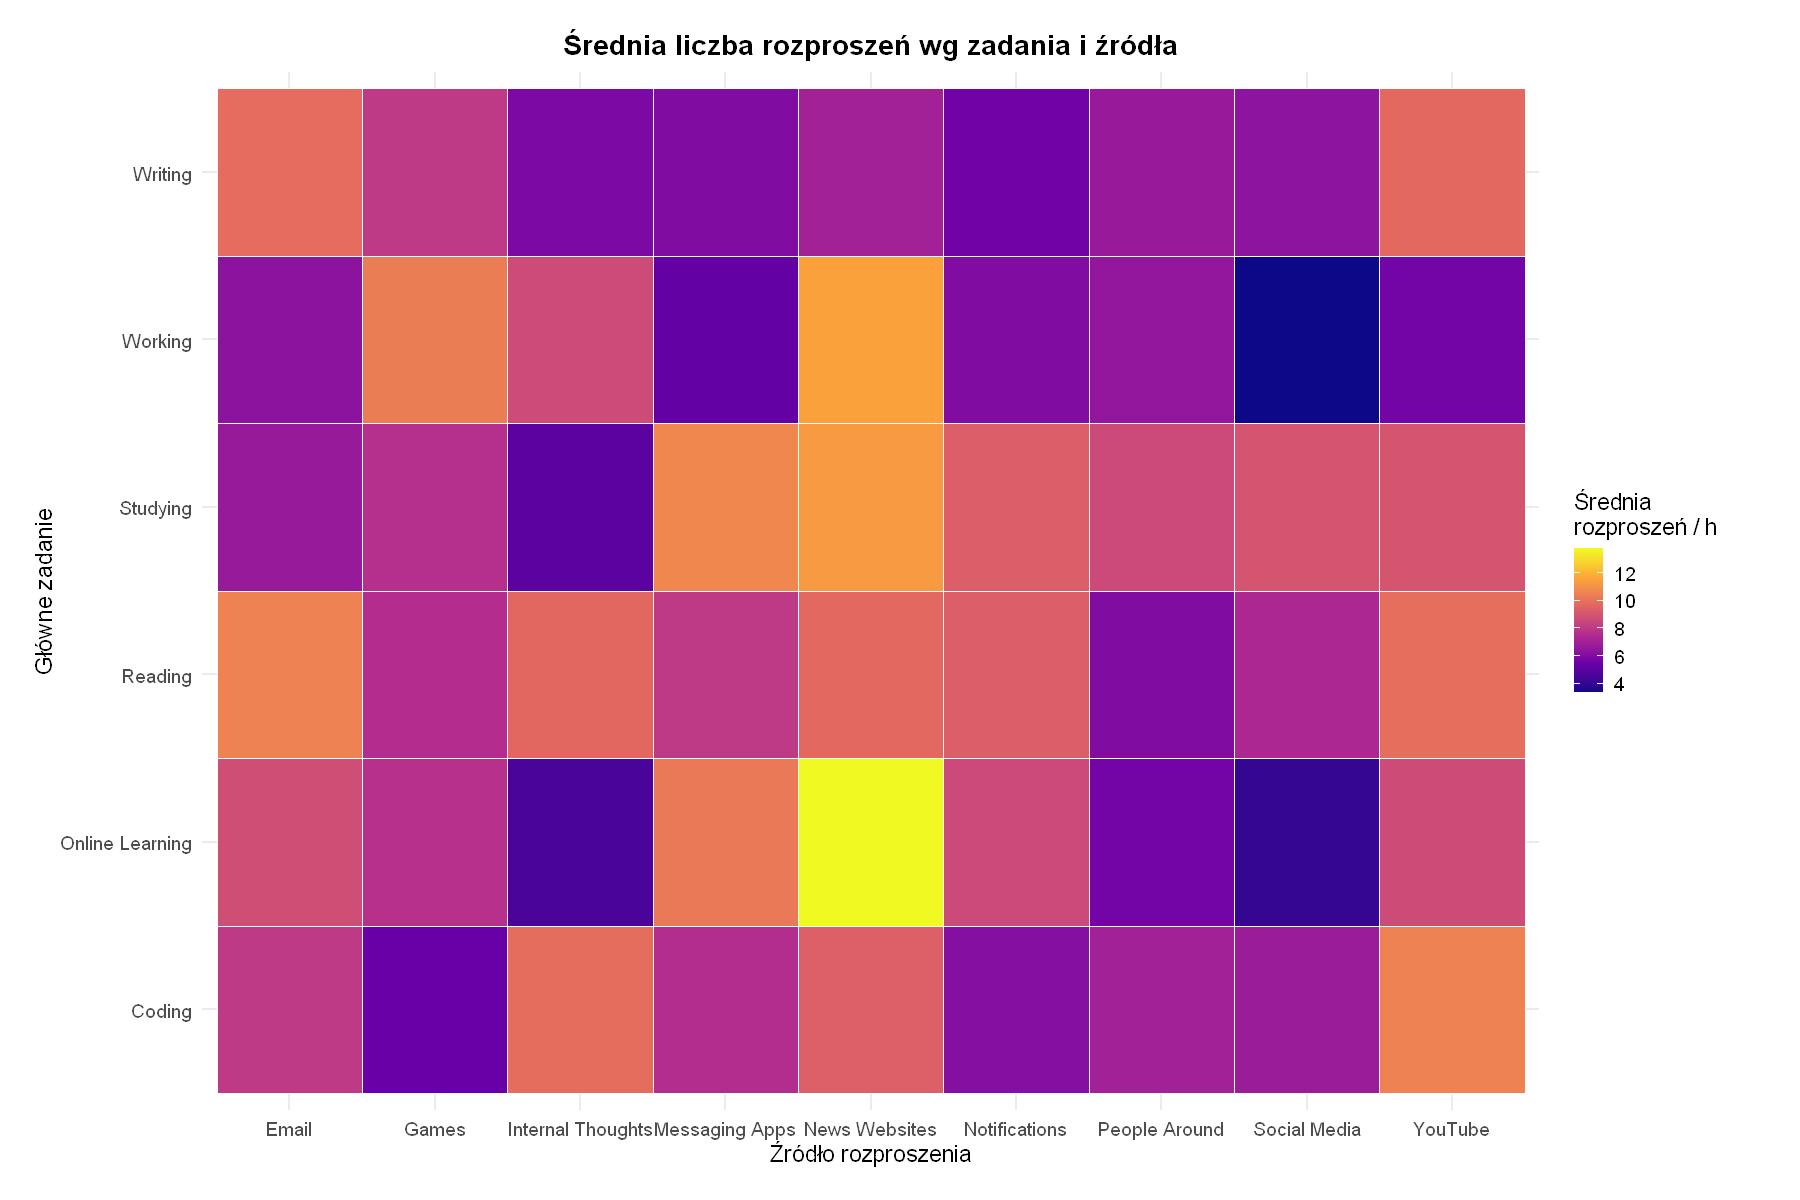

In [5]:
library(dplyr)

avg_freq <- data %>%
  group_by(primary_task, distraction_source) %>%
  summarise(mean_freq = mean(distraction_frequency_per_hour, na.rm = TRUE),
            .groups = "drop")

ggplot(avg_freq, aes(x = distraction_source,
                     y = primary_task,
                     fill = mean_freq)) +
  geom_tile(color = "white") +
  scale_fill_viridis_c(option = "C") +
  labs(
    title = "Średnia liczba rozproszeń wg zadania i źródła",
    x = "Źródło rozproszenia",
    y = "Główne zadanie",
    fill = "Średnia\nrozproszeń / h"
  )

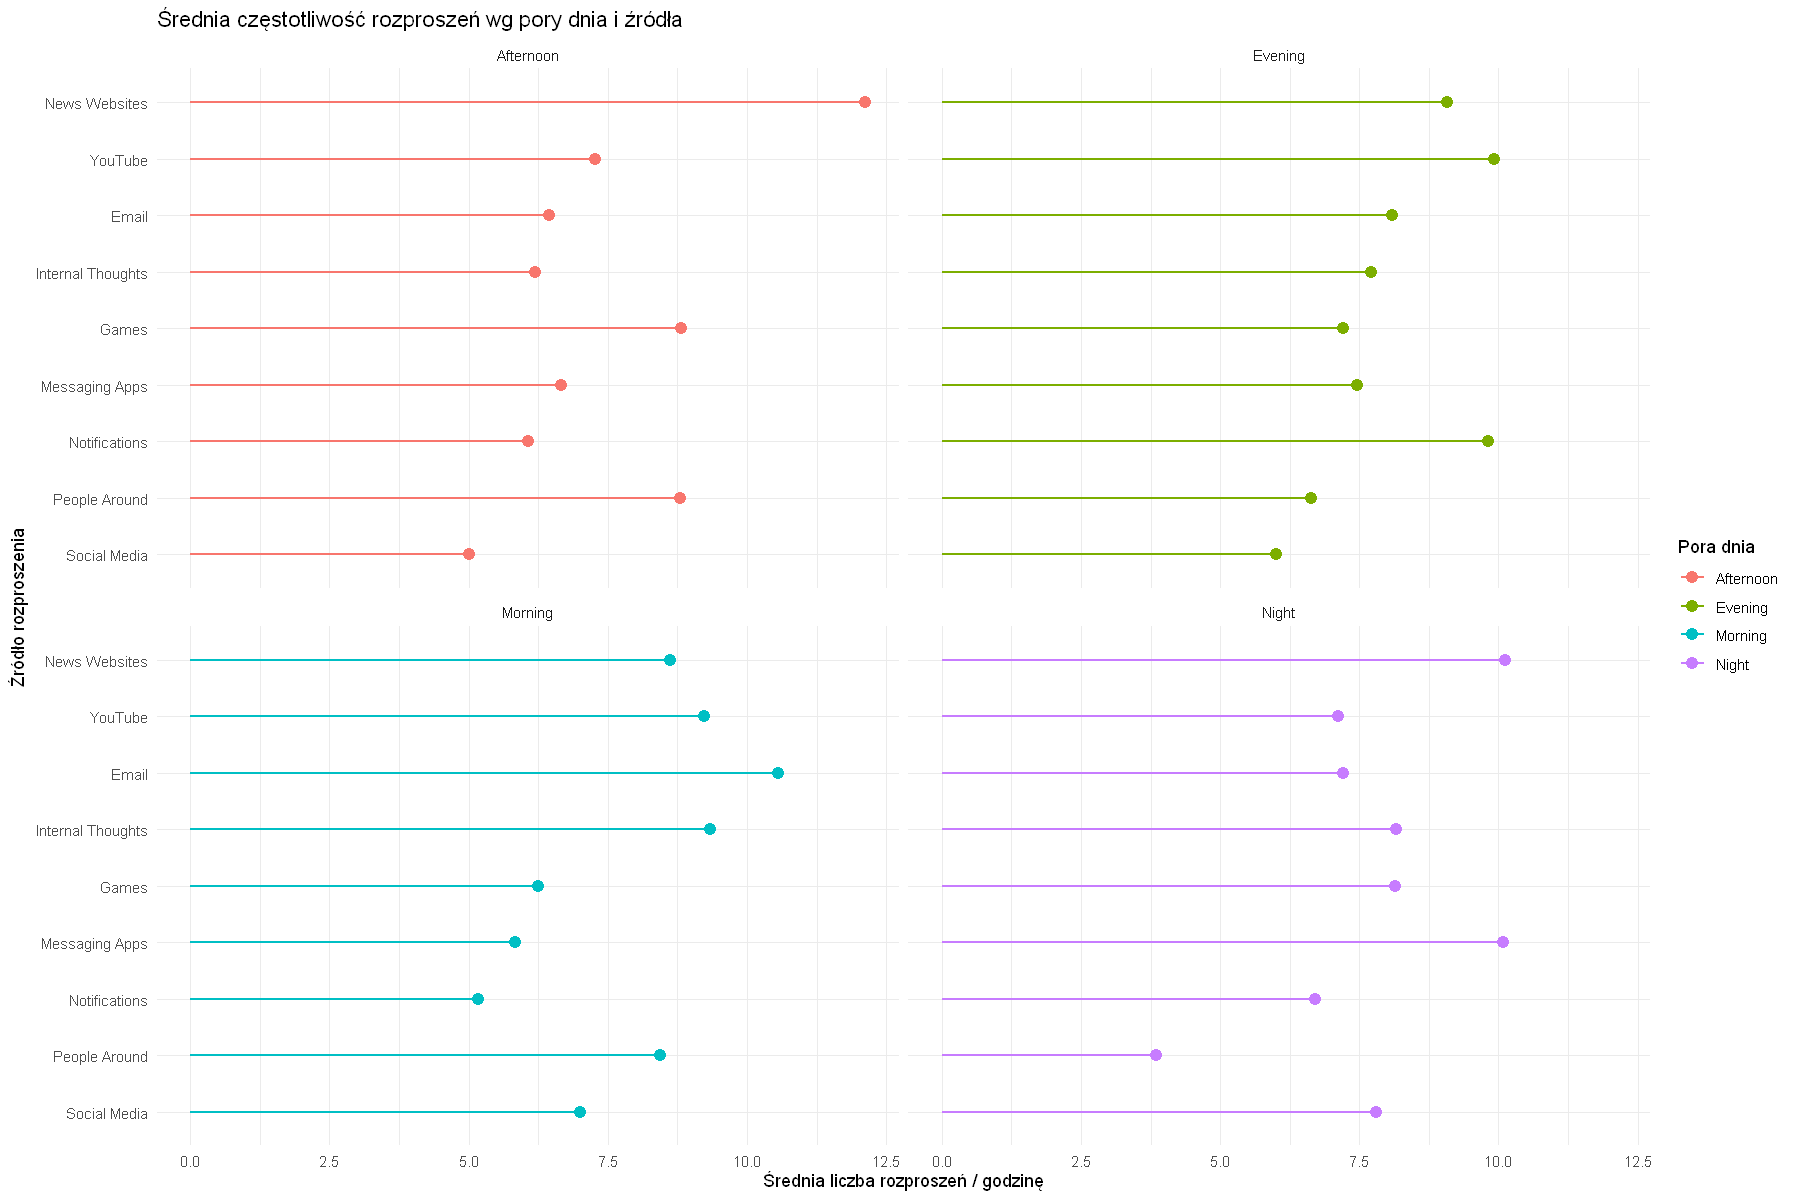

In [18]:
ggplot(freq_time_source,
       aes(x = mean_freq,
           y = reorder(distraction_source, mean_freq),
           color = time_of_day)) +
  geom_segment(aes(x = 0, xend = mean_freq,
                   yend = reorder(distraction_source, mean_freq)),
               linewidth = 0.7) +
  geom_point(size = 3) +
  facet_wrap(~ time_of_day) +
  labs(
    title = "Średnia częstotliwość rozproszeń wg pory dnia i źródła",
    x = "Średnia liczba rozproszeń / godzinę",
    y = "Źródło rozproszenia",
    color = "Pora dnia"
  ) +
  theme_minimal()

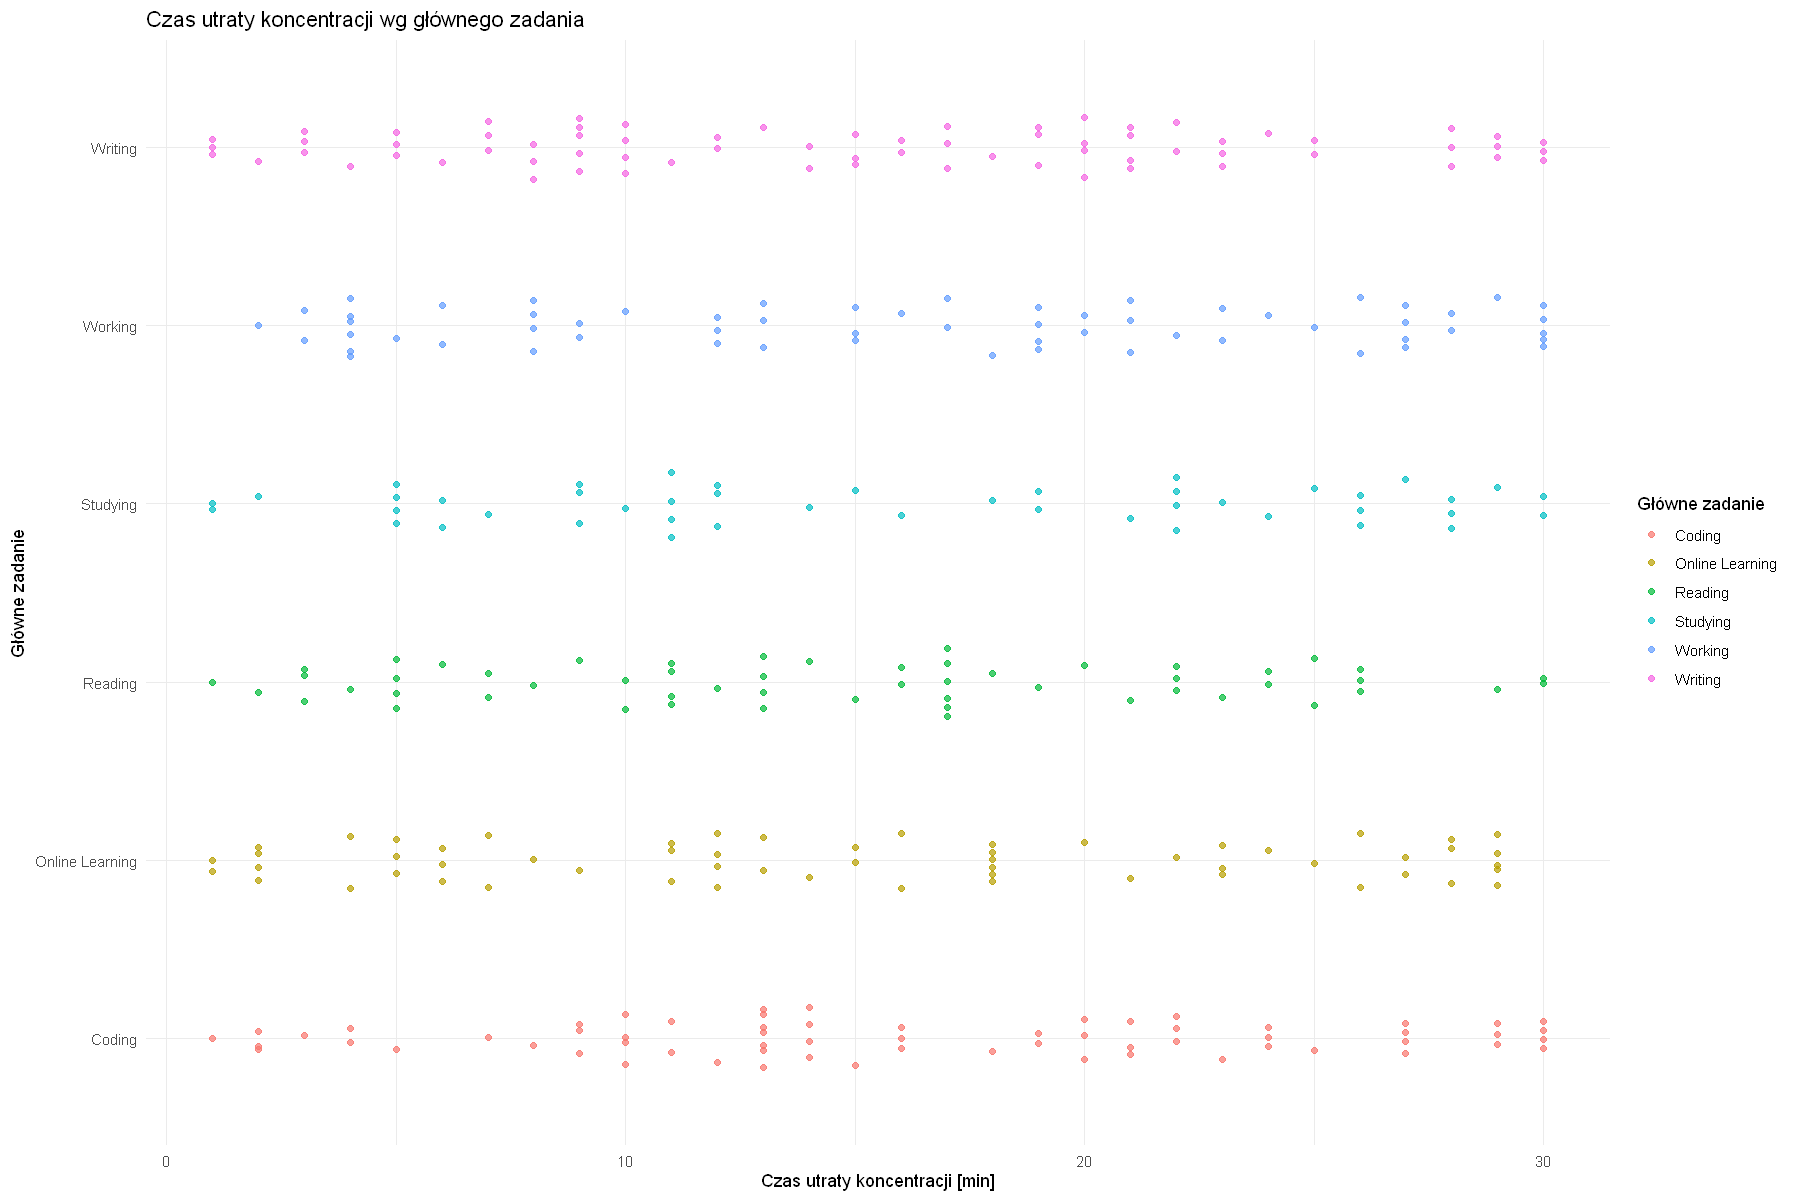

In [21]:
ggplot(data, aes(x = primary_task,
                 y = focus_loss_duration_minutes,
                 color = primary_task)) +
  geom_quasirandom(alpha = 0.7, width = 0.2) +
  coord_flip() +
  labs(
    title = "Czas utraty koncentracji wg głównego zadania",
    x = "Główne zadanie",
    y = "Czas utraty koncentracji [min]",
    color = "Główne zadanie"
  ) +
  theme_minimal()

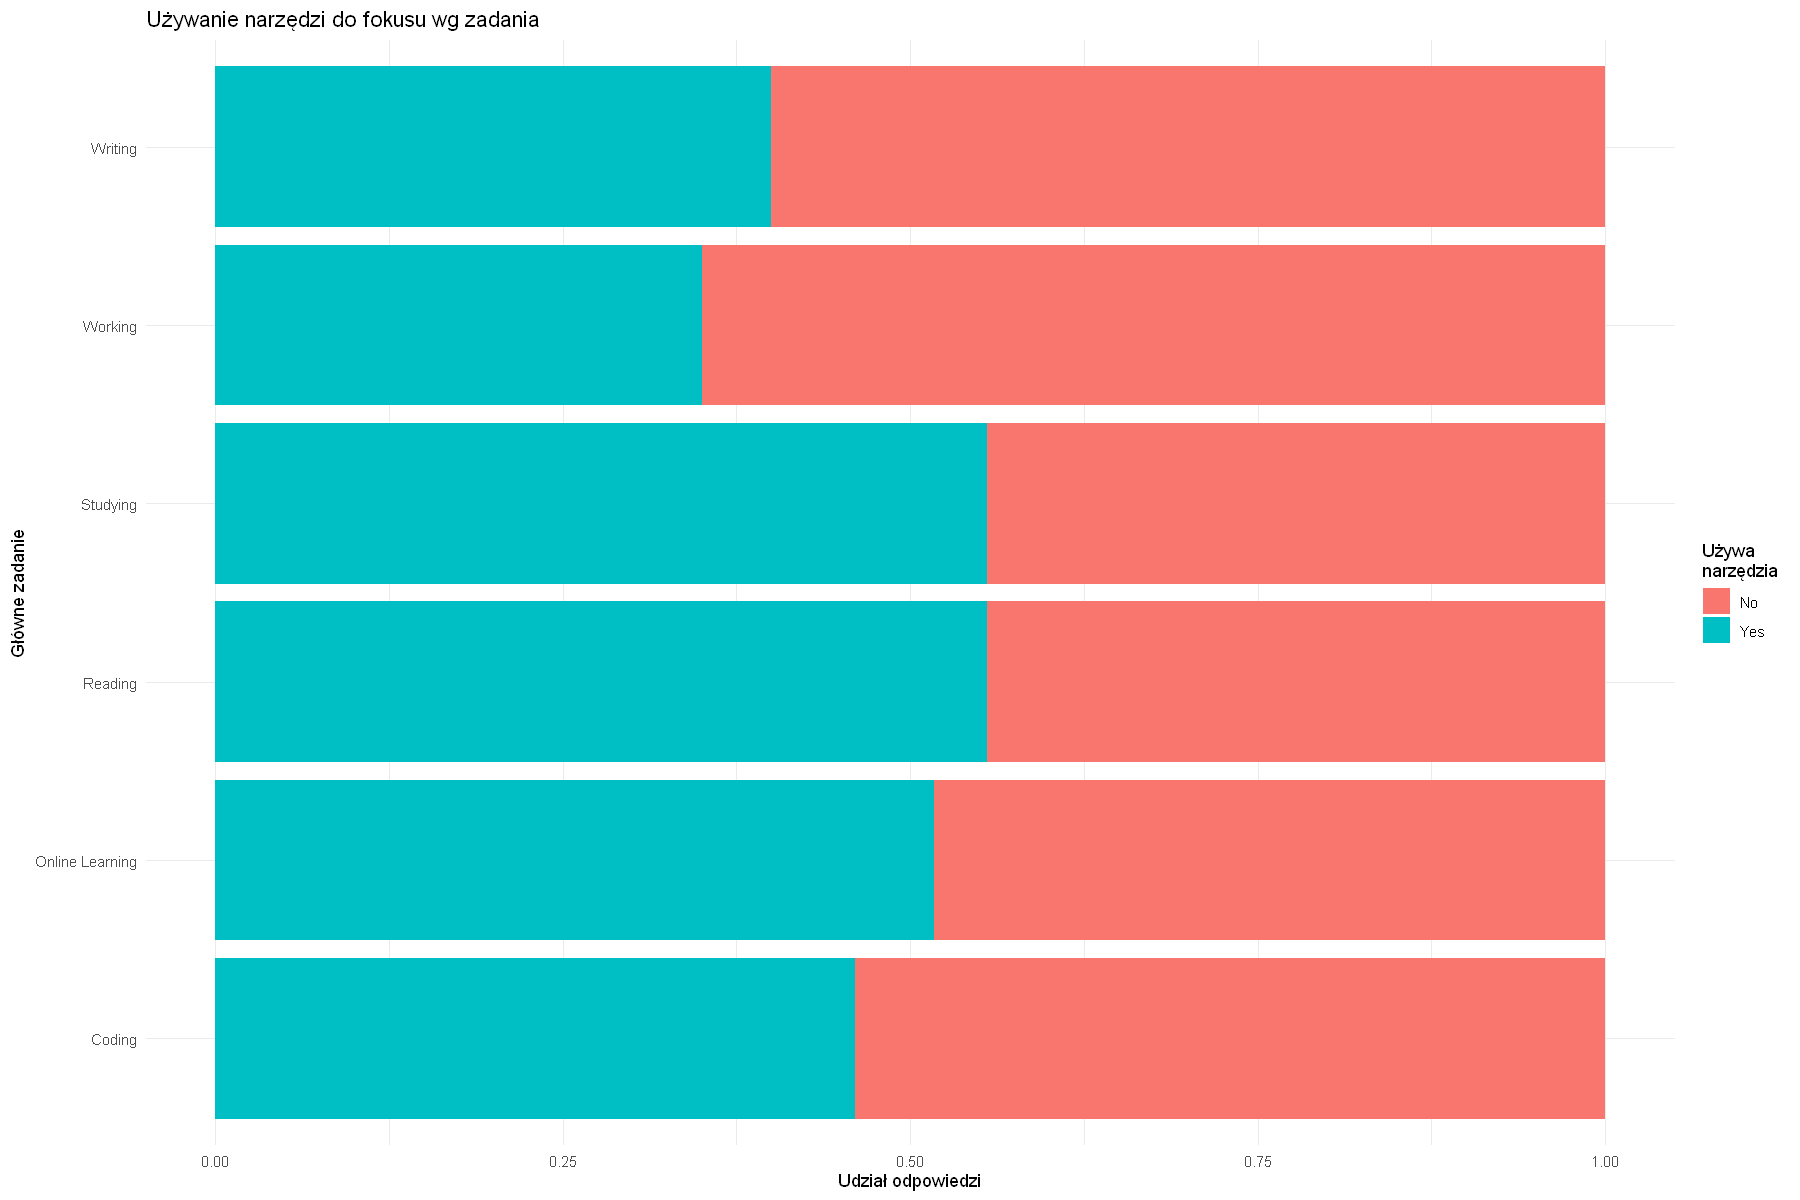

In [23]:
library(dplyr)

focus_tool_by_task <- data %>%
  group_by(primary_task, uses_focus_tool) %>%
  summarise(n = n(), .groups = "drop") %>%
  group_by(primary_task) %>%
  mutate(prop = n / sum(n))

ggplot(focus_tool_by_task,
       aes(x = primary_task,
           y = prop,
           fill = uses_focus_tool)) +
  geom_col() +
  coord_flip() +
  labs(
    title = "Używanie narzędzi do fokusu wg zadania",
    x = "Główne zadanie",
    y = "Udział odpowiedzi",
    fill = "Używa\nnarzędzia"
  ) +
  theme_minimal()

Warning message:
"package 'ggridges' was built under R version 4.5.3"


Picking joint bandwidth of 3.15



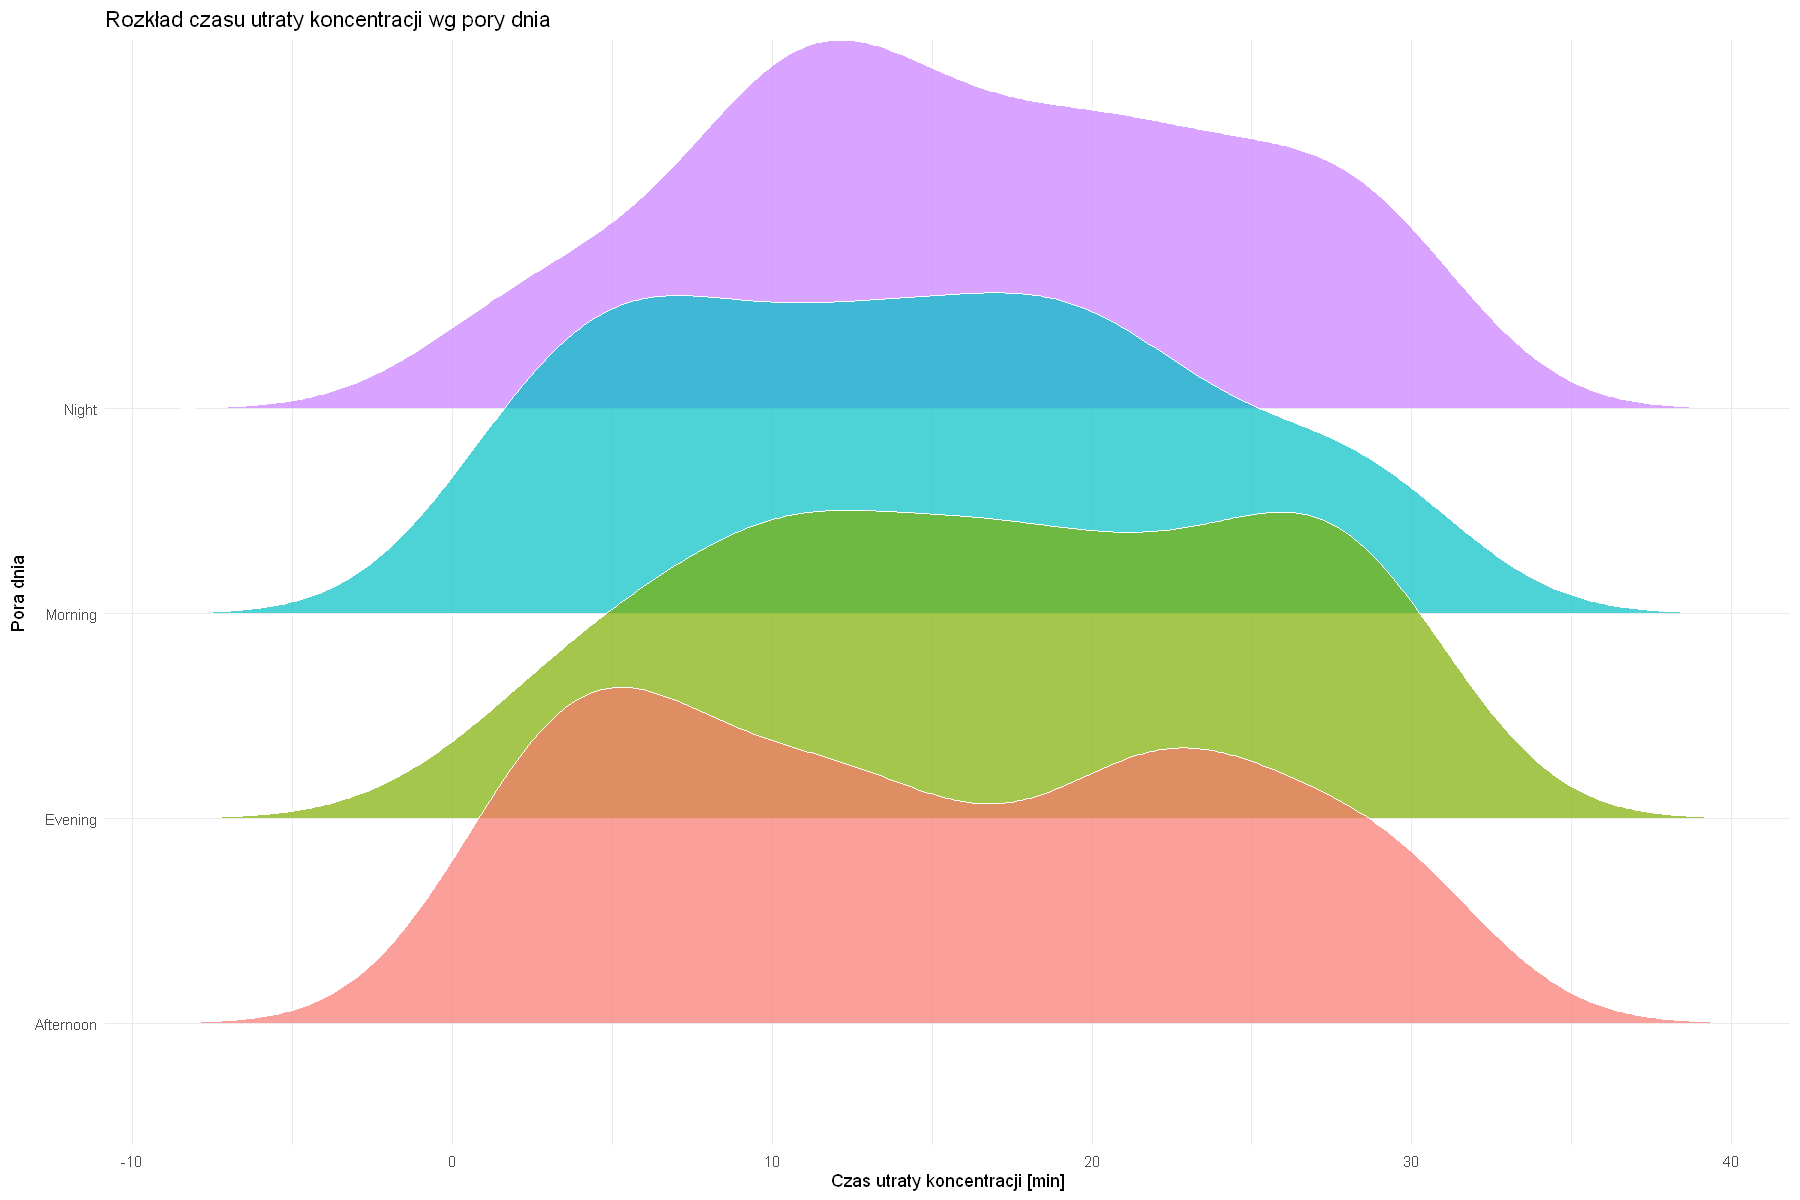

In [ ]:
library(ggridges)

ggplot(data,
       aes(x = focus_loss_duration_minutes,
           y = time_of_day,
           fill = time_of_day)) +
  geom_density_ridges(alpha = 0.7, color = "white") +
  labs(
    title = "Rozkład czasu utraty koncentracji wg pory dnia",
    x = "Czas utraty koncentracji [min]",
    y = "Pora dnia"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

`geom_smooth()` using formula = 'y ~ x'


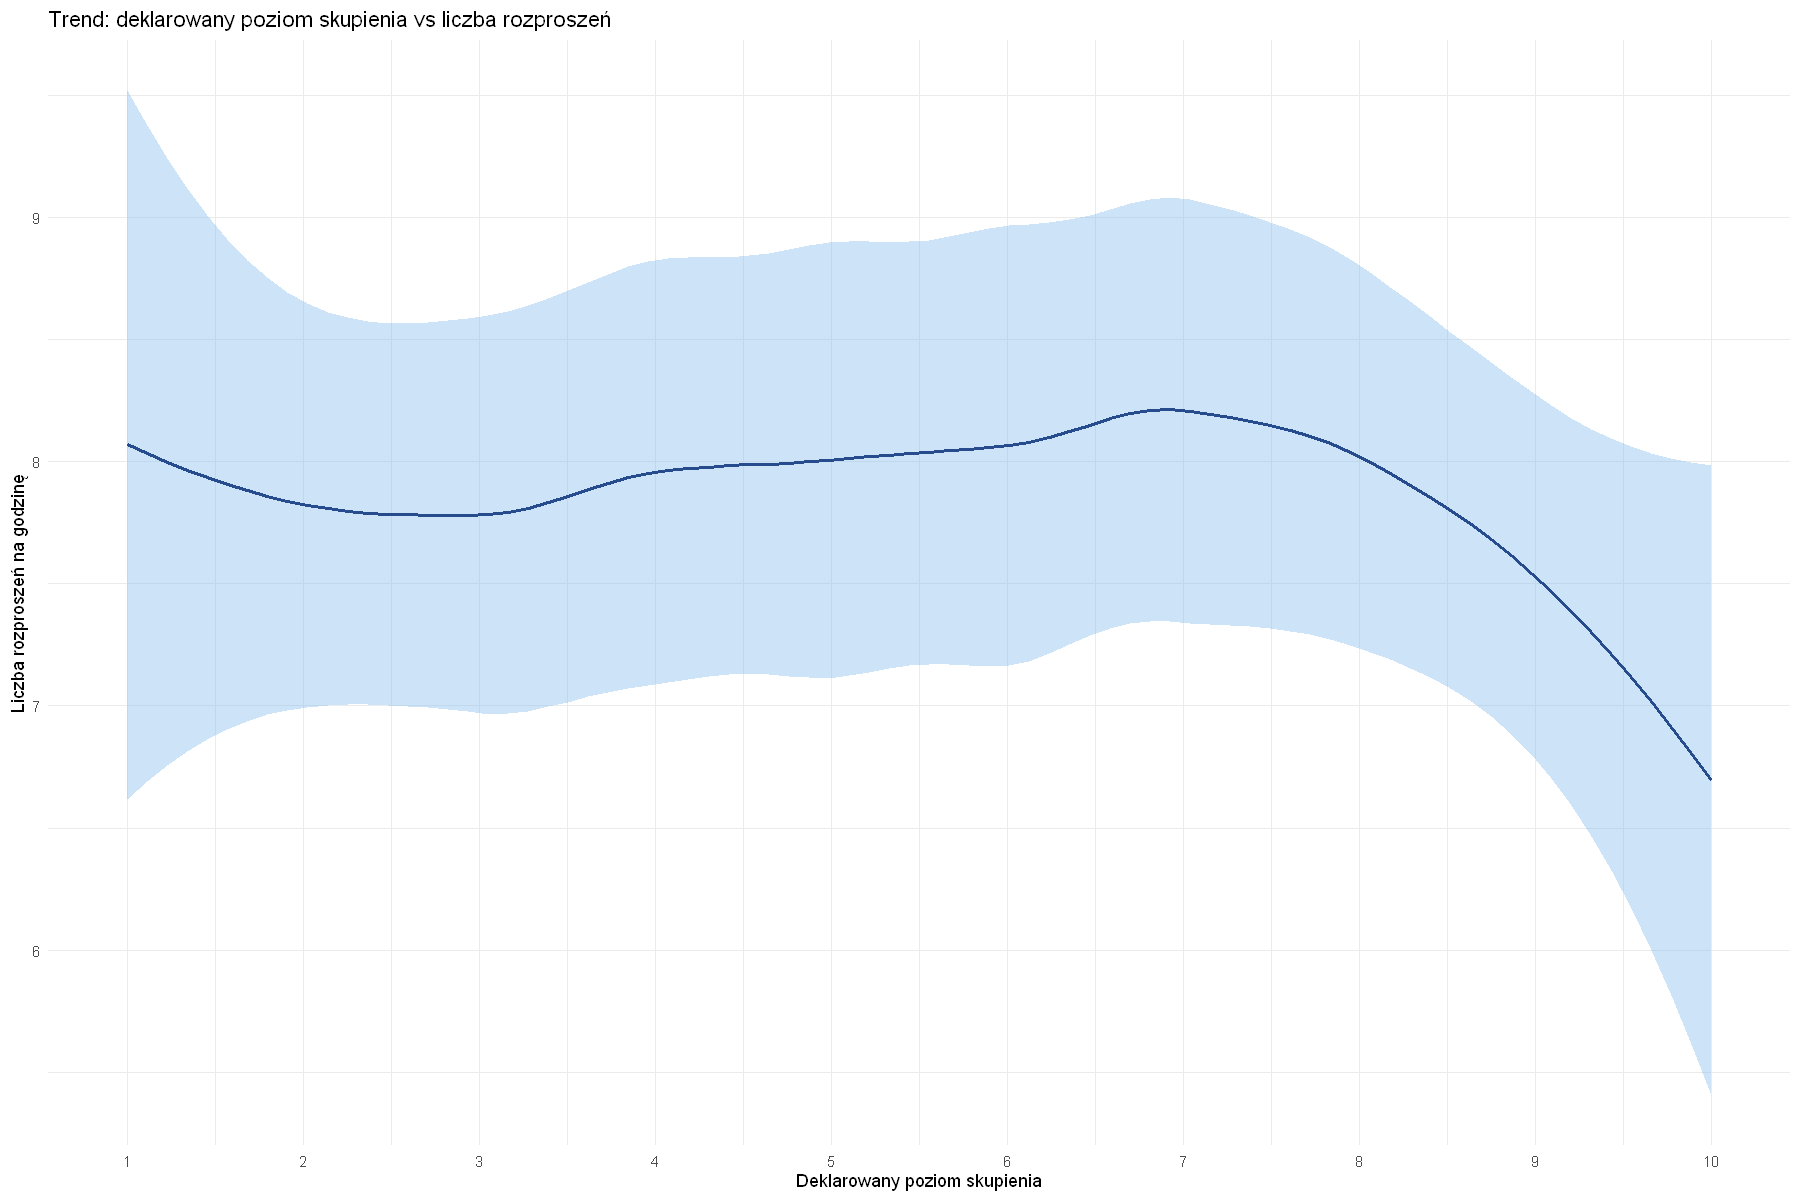

In [ ]:
# Zależność między deklarowanym poziomem focusu a liczbą rozproszeń
ggplot(data, aes(x = self_reported_focus_level,
                 y = distraction_frequency_per_hour)) +
  geom_smooth(method = "loess", se = TRUE,
              color = "#274c8d", fill = "#7fb8ee") +
  scale_x_continuous(breaks = sort(unique(data$self_reported_focus_level))) +
  labs(
    title = "Deklarowany poziom skupienia vs liczba rozproszeń",
    x = "Deklarowany poziom skupienia",
    y = "Liczba rozproszeń na godzinę"
  ) +
  theme_minimal()